# Laminar model comparison with single-shell and BEM forward models

We'll simulate a 20 Hz burst on the white matter surface of sub-104. Can we tell which surface generated the signal? We'll compare layer models twice on the same simulated data, first with an SPM single-shell forward model and then with an MNE boundary element model (BEM). We'll use the free-energy comparison from [Tutorial 02](https://danclab.github.io/laMEG/auto_tutorials/tutorial_02_model_comparison_free_energy.html) and [Bonaiuto et al. (2018)](https://doi.org/10.1016/j.neuroimage.2017.11.068).

## Setting up the simulation

The recording gives us the sensor positions and epoch timing. Run the notebook from the laMEG `tutorials` directory with the [test data](https://osf.io/x4zd3/download) in `../test_data`.

In [1]:
%env SUBJECTS_DIR=../test_data/fs

env: SUBJECTS_DIR=../test_data/fs


In [2]:
import os
import shutil
import numpy as np
import matplotlib.pyplot as plt
import tempfile
from IPython.display import Image
import base64

from lameg.forward import ForwardOperator, prepare_mne_forward
from lameg.invert import attach_forward_operator, coregister#, invert_ebb
from lameg.simulate import run_current_density_simulation
from lameg.laminar import model_comparison
from lameg.surf import LayerSurfaceSet
from lameg.util import load_meg_sensor_data, get_fiducial_coords
from lameg.viz import show_surface
import spm_standalone
import matlab

import mne
from mne.transforms import Transform, apply_trans

import nibabel as nib

# Subject information for data to base the simulations on
subj_id = 'sub-104'
ses_id = 'ses-01'

# Fiducial coil coordinates
fid_coords = get_fiducial_coords(subj_id, '../test_data/participants.tsv')

# Data file to base simulations on
data_file = os.path.join(
    '../test_data', 
    subj_id, 
    'meg',
    ses_id, 
    f'spm/spm-converted_autoreject-{subj_id}-{ses_id}-001-btn_trial-epo.mat'
)
fif_file=os.path.join(
    '../test_data', 
    subj_id, 
    'meg', 
    ses_id, 
    'mne',
    f'autoreject-{subj_id}-{ses_id}-001-btn_trial-epo.fif')
info = mne.io.read_info(fif_file)

spm = spm_standalone.initialize()

    Read 5 compensation matrices


The simulations will be based on a forward model using the multilayer mesh, and the model comparison will use each layer mesh

In [3]:
surf_set_bilam = LayerSurfaceSet(subj_id, 2)
surf_set = LayerSurfaceSet(subj_id, 11)

We're going to copy the data file to a temporary directory and direct all output there.

In [4]:
# Extract base name and path of data file
data_path, data_file_name = os.path.split(data_file)
data_base = os.path.splitext(data_file_name)[0]

# Where to put simulated data
tmp_dir = tempfile.mkdtemp()

# Copy data files to tmp directory
shutil.copy(
    os.path.join(data_path, f'{data_base}.mat'), 
    os.path.join(tmp_dir, f'{data_base}.mat')
)
shutil.copy(
    os.path.join(data_path, f'{data_base}.dat'), 
    os.path.join(tmp_dir, f'{data_base}.dat')
)

# Construct base file name for simulations
base_fname = os.path.join(tmp_dir, f'{data_base}.mat')

## Building the BEM forward model

Obviously you will want to take more care when constructing a BEM model, but that is outside the scope of this tutorial. SPM and MNE use different MRI coordinate systems. We'll put the inner skull, cortex and MRI fiducials in FreeSurfer surface RAS, then match the MRI fiducials to their measured positions in the MEG head frame.

In [5]:
# Both MRI transforms start at the same voxel coordinates.
voxel_to_ras = nib.load(os.path.join(surf_set.subj_dir, 'mri', 'orig.mgz')).header.get_vox2ras_tkr()
voxel_to_native = nib.load(os.path.join(surf_set.subj_dir, 'mri', 'orig.nii')).affine
native_to_ras = voxel_to_ras @ np.linalg.inv(voxel_to_native)

mri_fids = [fid_coords[key] for key in ('nas', 'lpa', 'rpa')]
mri_fids = apply_trans(native_to_ras, mri_fids) / 1000  # MNE uses metres.
dig = info.get_montage().get_positions()
head_fids = [dig[key] for key in ('nasion', 'lpa', 'rpa')]
trans = Transform('mri', 'head', mne.coreg.fit_matched_points(mri_fids, head_fids))

For the MEG forward model, we'll use a three-compartment BEM representing the brain, skull and scalp. The contours show the inner skull (red), outer skull (yellow) and scalp (orange) on the subject's MRI.

Overwriting existing file.
Overwriting existing file.
Overwriting existing file.
Creating the BEM geometry...
outer skin  CM is   2.26 -16.62  13.62 mm
outer skull CM is   2.20 -18.08  17.02 mm
inner skull CM is   2.40 -19.10  17.15 mm
Checking that surface outer skull is inside surface outer skin  ...
Checking that surface inner skull is inside surface outer skull ...
Nearest-neighbor searches will be significantly faster if scikit-learn is installed.
Checking distance between outer skin  and outer skull surfaces...
Minimum distance between the outer skin  and outer skull surfaces is approximately    7.2 mm
Nearest-neighbor searches will be significantly faster if scikit-learn is installed.
Checking distance between outer skull and inner skull surfaces...
Minimum distance between the outer skull and inner skull surfaces is approximately    1.4 mm
Surfaces passed the basic topology checks.
Complete.

Three-layer model surfaces loaded.
Computing the linear collocation solution...
    Ma

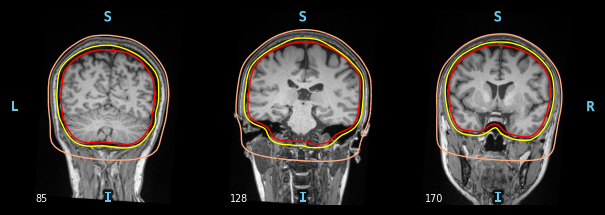

In [6]:
bem_dir = os.path.join(surf_set.subj_dir, 'bem')

# Use the three SPM boundaries at the same resolution.
surfaces = {
    'inner_skull': surf_set.load_head_mesh('iskull'),
    'outer_skull': surf_set.load_head_mesh('oskull'),
    'outer_skin': nib.load(os.path.join(surf_set.subj_dir, 'mri', 'origscalp_2562.surf.gii')),
}

for name, mesh in surfaces.items():
    vertices = apply_trans(native_to_ras, mesh.agg_data('pointset'))
    faces = mesh.agg_data('triangle')
    mne.write_surface(os.path.join(bem_dir, f'{name}.surf'), vertices, faces, overwrite=True)

model = mne.make_bem_model(
    subj_id,
    ico=None,
    conductivity=(0.3, 0.006, 0.3),  # brain, skull, scalp (S/m)
)

bem_solution = mne.make_bem_solution(model)

mne.viz.plot_bem(
    subject=subj_id, mri='orig.mgz',
    slices=[85, 128, 170], show=False,
)
plt.show()

We'll compute the lead field at every vertex on each downsampled surface. MNE computes three dipole components per location. laMEG projects them onto the same fixed cortical directions used by the single-shell model.

In [96]:
forwards = {}
for layer in surf_set.get_layer_names():
    mesh = surf_set.load(layer, stage='ds', orientation='link_vector', fixed=True)
    points = apply_trans(native_to_ras, mesh.agg_data('pointset')) / 1000
    # MNE requires a direction for each discrete point even when computing all three components.
    directions = np.tile([0., 0., 1.], (len(points), 1))
    src = mne.setup_volume_source_space(pos={'rr': points, 'nn': directions})
    forward = mne.make_forward_solution(info, trans, src, bem_solution, meg=True, eeg=False,
                                        mindist=0., ignore_ref=False)
    forwards[layer] = os.path.join(tmp_dir, f'{layer}-fwd.fif')
    mne.write_forward_solution(forwards[layer], forward, overwrite=True)
    del forward

Sphere                : origin at (0.0 0.0 0.0) mm
              radius  : 95.0 mm
Source location file  : dict()
Assuming input in millimeters
Assuming input in MRI coordinates

Positions (in meters) and orientations
51091 sources
Source space          : <SourceSpaces: [<discrete, n_used=51091>] MRI (surface RAS) coords, ~3.1 MB>
MRI -> head transform : instance of Transform
Measurement data      : instance of Info
Conductor model   : instance of ConductorModel
Accurate field computations
Do computations in head coordinates
Free source orientations

Read 1 source spaces a total of 51091 active source locations

Coordinate transformation: MRI (surface RAS) -> head
     0.995616  0.056208 -0.074757      -0.56 mm
    -0.029827  0.948357  0.315801      19.70 mm
     0.088647 -0.312187  0.945876      33.88 mm
     0.000000  0.000000  0.000000       1.00

Read 303 MEG channels from info
Read 29 MEG compensation channels from info
5 compensation data sets in info
Setting up compensation data

[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.


    Found   593/38949 points outside using solid angles
    Total 46504/51091 points inside the surface
Interior check completed in 37373.5 ms
    4587 source space points omitted because they are outside the inner skull surface.

Checking surface interior status for 303 points...
    Found   0/303 points inside  an interior sphere of radius   82.9 mm
    Found 298/303 points outside an exterior sphere of radius  110.5 mm
    Found   5/  5 points outside using surface Qhull


[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:   37.2s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:   37.2s finished
[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.


    Found   0/  0 points outside using solid angles
    Total 0/303 points inside the surface
Interior check completed in 295.5 ms

Composing the field computation matrix...


[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.3s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.3s finished
[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.9s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.9s finished
[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.8s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.8s finished
[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.7s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.7s finished
[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    2.0s remaining:    0

... (79 outputs left out)

[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.3s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.3s finished
[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.7s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.7s finished
[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    2.1s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    2.1s finished
[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.7s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.7s finished
[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.9s remaining:    0

Computing MEG at 50651 source locations (free orientations)...


[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.4s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.4s finished
[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:   35.6s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:   35.6s finished



Finished.
Overwriting existing file.
    Write a source space...
    [done]
    1 source spaces written


Coregister subject's data using the multilayer mesh

In [97]:
# Coregister data to multilayer mesh
skull_fname = os.path.join(surf_set.subj_dir, 'mri', 'origiskull_2562.surf.gii')
coregister(
    fid_coords, 
    base_fname,
    surf_set,
    iskull_fname=skull_fname, 
    spm_instance=spm
)

SPM, version dev (standalone)
MATLAB, version 9.6.0.1472908 (R2019a) Update 9
 ___  ____  __  __                                            
/ __)(  _ \(  \/  )                                           
\__ \ )___/ )    (   Statistical Parametric Mapping           
(___/(__)  (_/\/\_)  SPM - https://www.fil.ion.ucl.ac.uk/spm/



------------------------------------------------------------------------
25-Nov-2026 12:00:03 - Running job #2
------------------------------------------------------------------------
25-Nov-2026 12:00:03 - Running 'Head model specification'

SPM: spm_eeg_inv_mesh_ui                           12:00:04 - 25/11/2026
multilayer.11.ds.link_vector.fixed
undoing the G3BR balancing for the gradiometer definition
creating layout from cfg.grad
undoing the G3BR balancing for the gradiometer definition
creating layout for ctf275 system

SPM: spm_eeg_inv_forward                           12:01:08 - 25/11/2026
Completed                               :          12:01:08 - 2

A vertex outside the skull at either depth drops out of both models. laMEG matches the shared locations and keeps their original cortical vertex numbers.

In [8]:
prepared = prepare_mne_forward(
    forwards, 
    surf_set,
    tmp_dir, 
    reference=base_fname, 
    info=info,
    ignore_ref=False, 
    allow_nominal_ctf_coils=True
)
bem = prepared.operator
print(f'{bem.n_columns:,} of {surf_set.get_vertices_per_layer():,} vertices retained per surface')

/home/bonaiuto/miniconda3/envs/lameg_dev/lib/python3.7/site-packages/ipykernel_launcher.py:8: UserWarning: Using 46504 of 51091 original cortical vertices at every depth. Vertices omitted by MNE (pial: 4587, 0.900: 4078, 0.800: 3574, 0.700: 3035, 0.600: 2508, 0.500: 2028, 0.400: 1526, 0.300: 1131, 0.200: 841, 0.100: 626, white: 440). See /home/bonaiuto/tmp/tmpsuj_ux7o/mne-forward-ygfid2wc/source_support.json.
  


46,504 of 51,091 vertices retained per surface


In [9]:
# Use the cortical surfaces retained by the BEM for simulation and model comparison.
surfaces = prepared.surfaces
mesh_fname = surfaces.get_mesh_path()
layer_names = surfaces.get_layer_names()
n_layers = len(layer_names)

## Building the single-shell forward model

We'll give SPM the same inner skull and the same retained pial and white vertices. SPM uses the measured CTF pickup geometry. MNE uses the nominal CTF coils for this acquisition.

In [10]:
coregister(
    fid_coords, base_fname, prepared.surfaces,
    forward_model_type='Single Shell', iskull_fname=skull_fname,
    viz=False, spm_instance=spm
)

# Ask SPM to compute the gain, then read it into laMEG.
modes_fname = os.path.join(tmp_dir, 'single_shell_modes.mat')
spm.spm_eeg_inv_prep_modes_xval(
    base_fname, matlab.double([]), modes_fname, 1.0, 0.0, nargout=0
)

single_shell = ForwardOperator.from_spm(
    base_fname, surfaces.get_mesh_path(), surfaces.get_layer_names(), allow_undefined_gain=True
)
models = [('Single shell', single_shell), ('BEM', bem)]

SPM, version dev (standalone)
MATLAB, version 9.6.0.1472908 (R2019a) Update 9
 ___  ____  __  __                                            
/ __)(  _ \(  \/  )                                           
\__ \ )___/ )    (   Statistical Parametric Mapping           
(___/(__)  (_/\/\_)  SPM - https://www.fil.ion.ucl.ac.uk/spm/



------------------------------------------------------------------------
22-Nov-2026 17:11:35 - Running job #1
------------------------------------------------------------------------
22-Nov-2026 17:11:35 - Running 'Head model specification'
multilayer.11.ds.link_vector.fixed

SPM: spm_eeg_inv_forward                           17:12:25 - 22/11/2026
Completed                               :          17:12:25 - 22/11/2026
22-Nov-2026 17:12:28 - Done    'Head model specification'
22-Nov-2026 17:12:28 - Done

Removed 0 bad channels, 274 total channels

Taking random selections of 0.00 percent of channels
Using maximum of 274 spatial modes

        SPM: spm_eeg_lga

## Simulating a signal
We're going to simulate 1s of a 20Hz sine wave with a dipole moment of 1nAm

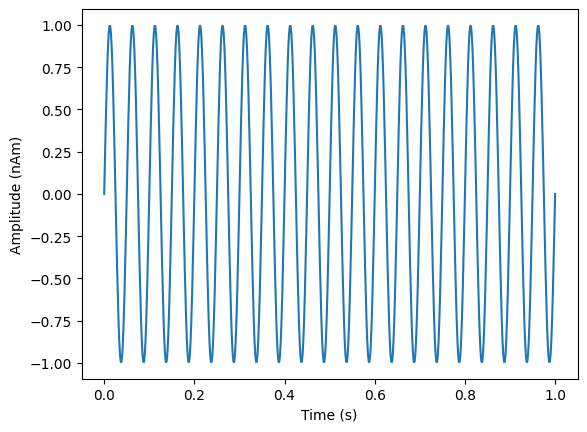

In [83]:
# Frequency of simulated sinusoid (Hz)
freq = 20
# Strength of simulated activity (nAm)
dipole_moment = 1
# Sampling rate (must match the data file)
s_rate = 600

# Generate 1s of a sine wave at a sampling rate of 600Hz (to match the data file)
time = np.linspace(0,1,s_rate+1)
sim_signal = np.sin(time*freq*2*np.pi).reshape(1,-1)

fig=plt.figure()
plt.plot(time,dipole_moment*sim_signal[0,:])
plt.xlabel('Time (s)')
plt.ylabel('Amplitude (nAm)')
plt.show()

In [85]:
# Vertex to simulate activity at
sim_vertex=44523

cam_view = [331, 26, -40,
            60, 37, 17,
            0.25, 0, 1]
plot = show_surface(
    surf_set,
    marker_vertices=sim_vertex,
    marker_size=5,
    camera_view=cam_view
)

Output()

In [86]:
plot.fetch_screenshot()

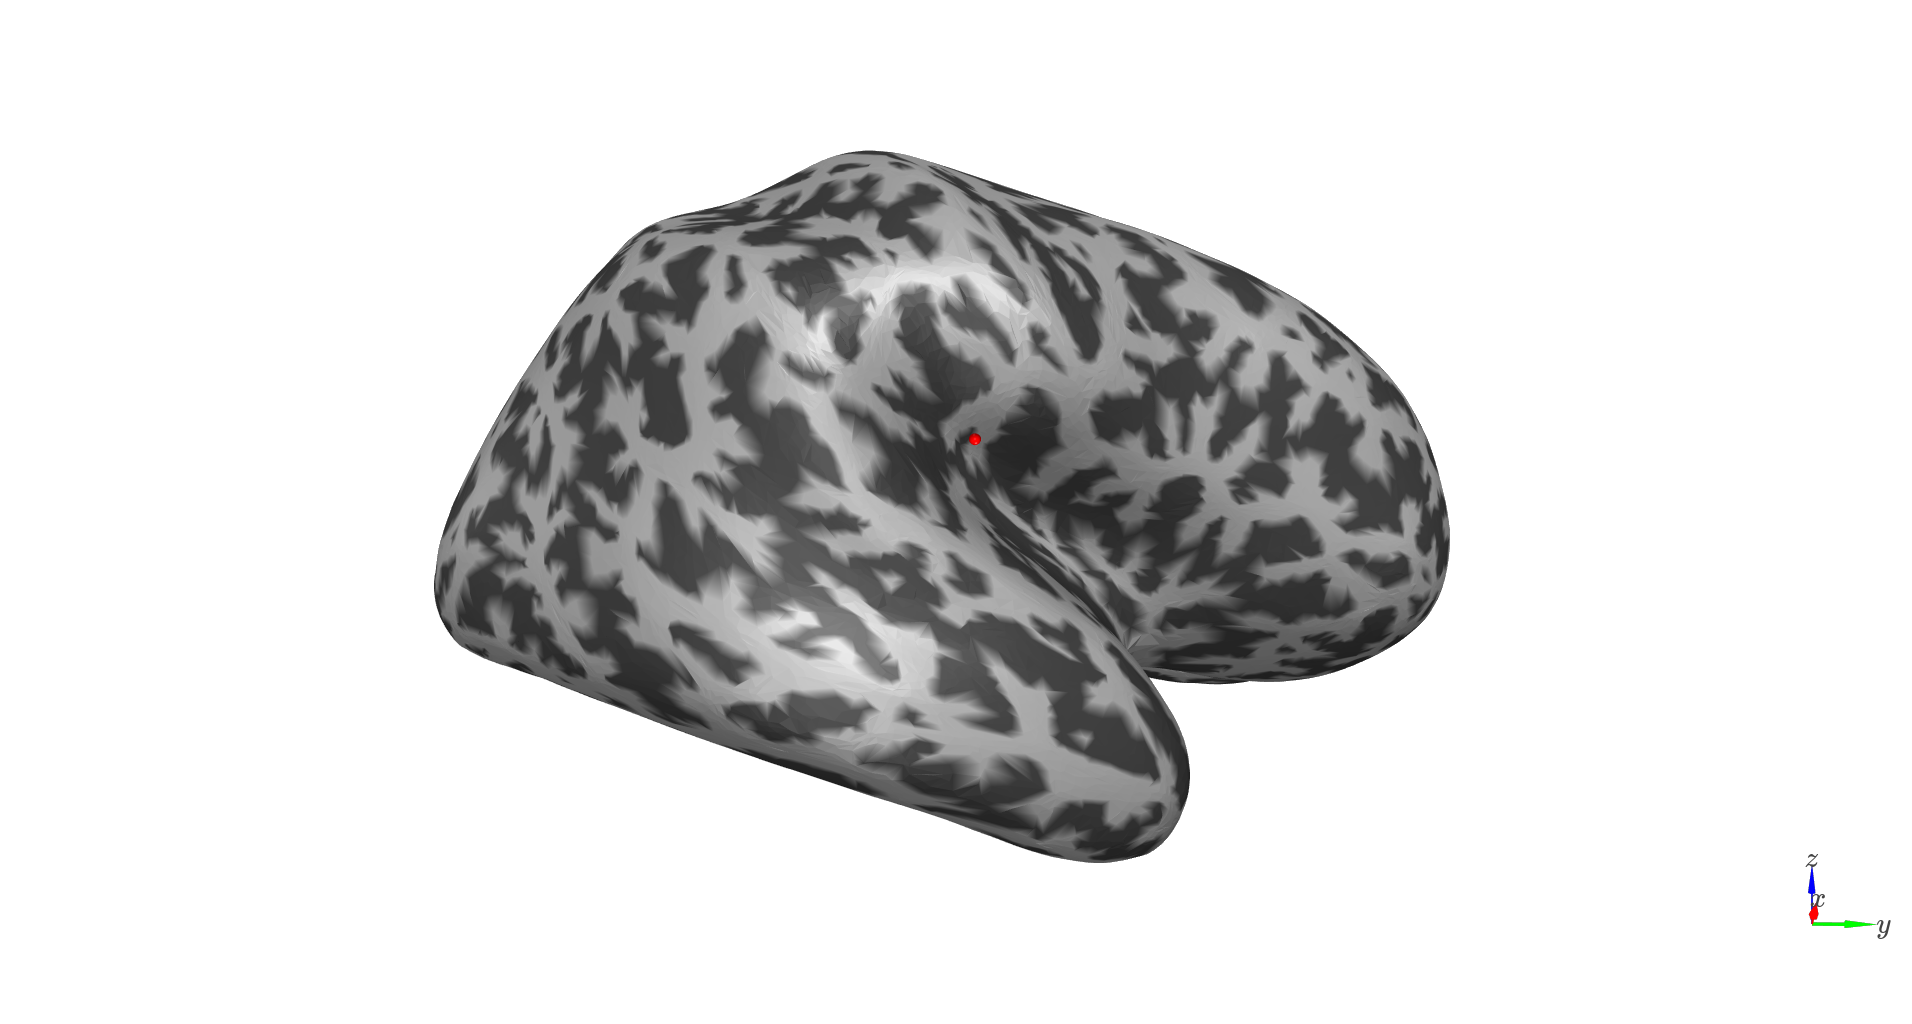

In [87]:
Image(data=base64.b64decode(plot.screenshot))

## Plotting the forward models

The first two maps shows the field that a 1 nA m dipole at this vertex produces at the sensors for each forward model. The map on the right shows BEM - single shell

Removing 5 compensators from info because not all compensation channels were picked.


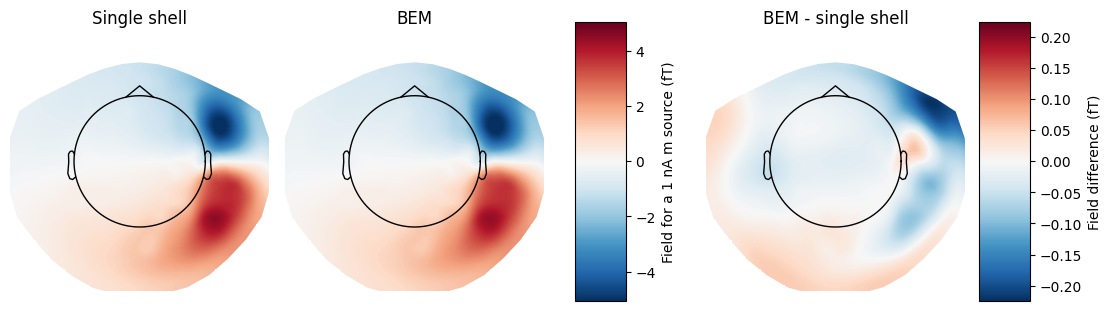

In [89]:
column = prepared.support.map_indices([sim_vertex])[0]

# Each subtraction must pair measurements from the same sensor.
assert tuple(single_shell.channel_names) == tuple(bem.channel_names)
fields = [forward.layer('white').gain[:, column] for _, forward in models]
difference = fields[1] - fields[0]

sensors = mne.pick_channels(info.ch_names, list(bem.channel_names), ordered=True)
sensor_info = mne.pick_info(info, sensors)

fig, axes = plt.subplots(1, 3, figsize=(11, 3), constrained_layout=True)
topomap = dict(ch_type='mag', show=False, cmap='RdBu_r', contours=0, sensors=False)

# Use the same limits for both forward models so their amplitudes are comparable.
limit = np.max(np.abs(fields))
for ax, (name, _), field in zip(axes[:2], models, fields):
    im, _ = mne.viz.plot_topomap(
        field, sensor_info, axes=ax, vlim=(-limit, limit), **topomap
    )
    ax.set_title(name)
fig.colorbar(im, ax=axes[:2], label='Field for a 1 nA m source (fT)')

# Subtract the signed fields at the sensors before interpolating the difference.
diff_limit = np.max(np.abs(difference)) or limit
im_diff, _ = mne.viz.plot_topomap(
    difference, sensor_info, axes=axes[2], vlim=(-diff_limit, diff_limit), **topomap
)
axes[2].set_title('BEM - single shell')
fig.colorbar(im_diff, ax=axes[2], label='Field difference (fT)')
plt.show()

## BEM simulation in each layer with model comparison across layers using each forward model
Simulate on each layer using BEM, and for each simulation, run model comparison across all layers. Once using the single shell model and once using the BEM

In [93]:
# Select the BEM gain in the SPM recording used by the simulator.
attach_forward_operator(base_fname, bem, 0, spm, mesh_fname)

# Size of simulated patch of activity (mm)
sim_patch_size = 5
# SNR of simulated data (dB)
SNR = -5

# Rows are simulated layers and columns are evaluated layers.
all_layerF = {
    name: np.full((surf_set.n_layers, surf_set.n_layers), np.nan)
    for name, _ in models
}

for l, layer in enumerate(layer_names):
    print(f'Simulating on layer {l} ({layer})')
    l_vertex = surfaces.get_multilayer_vertex(layer, column)

    l_sim_fname = run_current_density_simulation(
        base_fname, f'sim_{sim_vertex}_{l}_', l_vertex,
        sim_signal, dipole_moment, sim_patch_size, SNR,
        viz=False, spm_instance=spm
    )
    layer_F = {}
    for name, forward in models:
        F, _ = model_comparison(
            fid_coords, l_sim_fname, surfaces,
            forward_operator=forward,
            forward_kwargs={'iskull_fname': skull_fname},
            invert_kwargs={'patch_size': 5, 'n_temp_modes': 4},
            viz=False, spm_instance=spm
        )
        layer_F[name] = F

    for name, F in layer_F.items():
        all_layerF[name][l, :] = F

Simulating on layer 0 (pial)
SPM, version dev (standalone)
MATLAB, version 9.6.0.1472908 (R2019a) Update 9
 ___  ____  __  __                                            
/ __)(  _ \(  \/  )                                           
\__ \ )___/ )    (   Statistical Parametric Mapping           
(___/(__)  (_/\/\_)  SPM - https://www.fil.ion.ucl.ac.uk/spm/

Simulating data on MEG channels only
Using closest mesh vertices to the specified coordinates
Furthest distance from dipole location to mesh 0.00 mm

ans =

    'm'

SIMULATING CURRENT DISTRIBUTIONS ON MESH
Computing Gain Matrix:  - done
Saving prior in directory /home/bonaiuto/tmp/tmpsuj_ux7o/simprior_sim_44523_0_spm-converted_autoreject-sub-104-ses-01-001-btn_trial-epo
Using 1 iterations of 1 fixed patches

 In last iteration...setting up patch 1 with  1.00 nAm , FWHM 5.00mm, mean moment density 51.70 pAm/mm2, peak momemnt density 164.48 pAm/mm2 
Prior 1. Average Mean (over dist of FWHM from centre) moment density 51.70, sd 0.00 pA



------------------------------------------------------------------------
25-Nov-2026 07:57:27 - Running job #2
------------------------------------------------------------------------
25-Nov-2026 07:57:27 - Running 'Source inversion, iterative'
Loading spatial modes from file
Using testchans defined in spatial modes file

gainname =

    'lameg_gain_63898d5b31ec09d219cf675d26af971a347a563c9b33ece03365261429055198.mat'

Checking leadfieldsReseting random number seed ! and then generating random patch centres 
patchiter 1/1
Checking leadfields
ans =

    0.2912    0.3234
    0.2028    0.7779

 - done

Found smoothfile /home/bonaiuto/tmp/tmpsuj_ux7o/mne-forward-ygfid2wc/FWHM5.00_0.900.ds.link_vector.fixed.mat, not recomputing
 - done
Optimising and aligning spatial modes ...
Using pre-specified spatial modes
Using 274 spatial modesNumber of samples 601
Fixed number of temporal modes
Using 4 temporal modes, accounting for 42.58 percent average variance
NB smooth EBB algorithm !
Using 1 s

Smoothing /home/bonaiuto/tmp/tmpsuj_ux7o/mne-forward-ygfid2wc/0.700.ds.link_vector.fixed.gii

smoothmeshname =

    '/home/bonaiuto/tmp/tmpsuj_ux7o/mne-forward-ygfid2wc/FWHM5.00_0.700.ds.link_vector.fixed.mat'


Found smoothfile /home/bonaiuto/tmp/tmpsuj_ux7o/mne-forward-ygfid2wc/FWHM5.00_0.700.ds.link_vector.fixed.mat, not recomputing
Removed 0 bad channels, 274 total channels

Taking random selections of 0.00 percent of channels
Using maximum of 274 spatial modes

Preparing modes file  block 1 of 1 for 274 training and 0 test chans

 saving spatial mode file /home/bonaiuto/tmp/tmpsuj_ux7o/sim_44523_0_spm-converted_autoreject-sub-104-ses-01-001-btn_trial-epo_testmodes.mat
SPM, version dev (standalone)
MATLAB, version 9.6.0.1472908 (R2019a) Update 9
 ___  ____  __  __                                            
/ __)(  _ \(  \/  )                                           
\__ \ )___/ )    (   Statistical Parametric Mapping           
(___/(__)  (_/\/\_)  SPM - https://www.fil.ion.ucl.



------------------------------------------------------------------------
25-Nov-2026 08:00:35 - Running job #2
------------------------------------------------------------------------
25-Nov-2026 08:00:35 - Running 'Head model specification'
0.500.ds.link_vector.fixed

SPM: spm_eeg_inv_forward                           08:01:05 - 25/11/2026
Completed                               :          08:01:06 - 25/11/2026
25-Nov-2026 08:01:07 - Done    'Head model specification'
25-Nov-2026 08:01:07 - Done

SPM, version dev (standalone)
MATLAB, version 9.6.0.1472908 (R2019a) Update 9
 ___  ____  __  __                                            
/ __)(  _ \(  \/  )                                           
\__ \ )___/ )    (   Statistical Parametric Mapping           
(___/(__)  (_/\/\_)  SPM - https://www.fil.ion.ucl.ac.uk/spm/

Smoothing /home/bonaiuto/tmp/tmpsuj_ux7o/mne-forward-ygfid2wc/0.500.ds.link_vector.fixed.gii

smoothmeshname =

    '/home/bonaiuto/tmp/tmpsuj_ux7o/mne-forward-ygfid

Inverting subject 1
  ReML Iteration 1                      :        ...3.102976e+04 [+4.12]
  ReML Iteration 2                      :        ...2.895373e+04 [+4.25]
  ReML Iteration 3                      :        ...2.504063e+04 [+4.38]
  ReML Iteration 4                      :        ...1.780562e+04 [+4.50]
  ReML Iteration 5                      :        ...8.063921e+03 [+4.62]
  ReML Iteration 6                      :        ...1.672079e-02 [+4.75]
  ReML Iteration 7                      :        ...9.094981e-05 [+4.88]
Percent variance explained 99.98 (42.57)
model evidences relative to maximum:

ans =

     0

25-Nov-2026 08:02:26 - Done    'Source inversion, iterative'
25-Nov-2026 08:02:26 - Done

SPM, version dev (standalone)
MATLAB, version 9.6.0.1472908 (R2019a) Update 9
 ___  ____  __  __                                            
/ __)(  _ \(  \/  )                                           
\__ \ )___/ )    (   Statistical Parametric Mapping           
(___/(__)  (_/\/\_

Checking leadfields
ans =

    0.2912    0.3234
    0.2028    0.7779

 - done

Found smoothfile /home/bonaiuto/tmp/tmpsuj_ux7o/mne-forward-ygfid2wc/FWHM5.00_0.200.ds.link_vector.fixed.mat, not recomputing
 - done
Optimising and aligning spatial modes ...
Using pre-specified spatial modes
Using 274 spatial modesNumber of samples 601
Fixed number of temporal modes
Using 4 temporal modes, accounting for 42.58 percent average variance
NB smooth EBB algorithm !
Using 1 spatial source priors provided
  ReML Iteration 1                      :        ...3.102757e+04 [+4.12]
  ReML Iteration 2                      :        ...2.895366e+04 [+4.25]
  ReML Iteration 3                      :        ...2.504347e+04 [+4.38]
  ReML Iteration 4                      :        ...1.780939e+04 [+4.50]
  ReML Iteration 5                      :        ...8.066955e+03 [+4.62]
  ReML Iteration 6                      :        ...1.615581e-02 [+4.75]
  ReML Iteration 7                      :        ...8.681233e-

... (114 outputs left out)

Inverting subject 1
  ReML Iteration 1                      :        ...3.106470e+04 [+4.12]
  ReML Iteration 2                      :        ...2.896266e+04 [+4.25]
  ReML Iteration 3                      :        ...2.499066e+04 [+4.38]
  ReML Iteration 4                      :        ...1.770101e+04 [+4.50]
  ReML Iteration 5                      :        ...7.953332e+03 [+4.62]
  ReML Iteration 6                      :        ...4.107611e+00 [+4.75]
  ReML Iteration 7                      :        ...3.549605e-02 [+4.88]
  ReML Iteration 8                      :        ...4.257234e-04 [+5.00]
Percent variance explained 99.98 (42.11)
model evidences relative to maximum:

ans =

     0

25-Nov-2026 11:34:53 - Done    'Source inversion, iterative'
25-Nov-2026 11:34:53 - Done

SPM, version dev (standalone)
MATLAB, version 9.6.0.1472908 (R2019a) Update 9
 ___  ____  __  __                                            
/ __)(  _ \(  \/  )                                           
\__ \ )_

Loading spatial modes from file
Using testchans defined in spatial modes file

gainname =

    'lameg_gain_456adf5fa3982bbfceb439ddedc1021138b3e9f598ec2a39aee3cb0d8d90c0af.mat'

Checking leadfieldsReseting random number seed ! and then generating random patch centres 
patchiter 1/1
Checking leadfields
ans =

    0.2912    0.3234
    0.2028    0.7779

 - done

Found smoothfile /home/bonaiuto/tmp/tmpsuj_ux7o/mne-forward-ygfid2wc/FWHM5.00_0.400.ds.link_vector.fixed.mat, not recomputing
 - done
Optimising and aligning spatial modes ...
Using pre-specified spatial modes
Using 274 spatial modesNumber of samples 601
Fixed number of temporal modes
Using 4 temporal modes, accounting for 42.11 percent average variance
NB smooth EBB algorithm !
Using 1 spatial source priors provided
  ReML Iteration 1                      :        ...3.111933e+04 [+4.12]
  ReML Iteration 2                      :        ...2.903236e+04 [+4.25]
  ReML Iteration 3                      :        ...2.505981e+04 [+4.38

Removed 0 bad channels, 274 total channels

Taking random selections of 0.00 percent of channels
Using maximum of 274 spatial modes

Preparing modes file  block 1 of 1 for 274 training and 0 test chans

 saving spatial mode file /home/bonaiuto/tmp/tmpsuj_ux7o/sim_44523_9_spm-converted_autoreject-sub-104-ses-01-001-btn_trial-epo_testmodes.mat
SPM, version dev (standalone)
MATLAB, version 9.6.0.1472908 (R2019a) Update 9
 ___  ____  __  __                                            
/ __)(  _ \(  \/  )                                           
\__ \ )___/ )    (   Statistical Parametric Mapping           
(___/(__)  (_/\/\_)  SPM - https://www.fil.ion.ucl.ac.uk/spm/



------------------------------------------------------------------------
25-Nov-2026 11:38:20 - Running job #2
------------------------------------------------------------------------
25-Nov-2026 11:38:20 - Running 'Source inversion, iterative'
Loading spatial modes from file
Using testchans defined in spatial modes file



white.ds.link_vector.fixed

SPM: spm_eeg_inv_forward                           11:40:06 - 25/11/2026
Completed                               :          11:40:07 - 25/11/2026
25-Nov-2026 11:40:08 - Done    'Head model specification'
25-Nov-2026 11:40:08 - Done

SPM, version dev (standalone)
MATLAB, version 9.6.0.1472908 (R2019a) Update 9
 ___  ____  __  __                                            
/ __)(  _ \(  \/  )                                           
\__ \ )___/ )    (   Statistical Parametric Mapping           
(___/(__)  (_/\/\_)  SPM - https://www.fil.ion.ucl.ac.uk/spm/

Smoothing /home/bonaiuto/tmp/tmpsuj_ux7o/mne-forward-ygfid2wc/white.ds.link_vector.fixed.gii

smoothmeshname =

    '/home/bonaiuto/tmp/tmpsuj_ux7o/mne-forward-ygfid2wc/FWHM5.00_white.ds.link_vector.fixed.mat'


Found smoothfile /home/bonaiuto/tmp/tmpsuj_ux7o/mne-forward-ygfid2wc/FWHM5.00_white.ds.link_vector.fixed.mat, not recomputing
Removed 0 bad channels, 274 total channels

Taking random selections of

For each simulation, we can plot the free energy for all models relative to the worst model. The layer model with the highest free energy should correspond to the layer that the activity was simulated in.

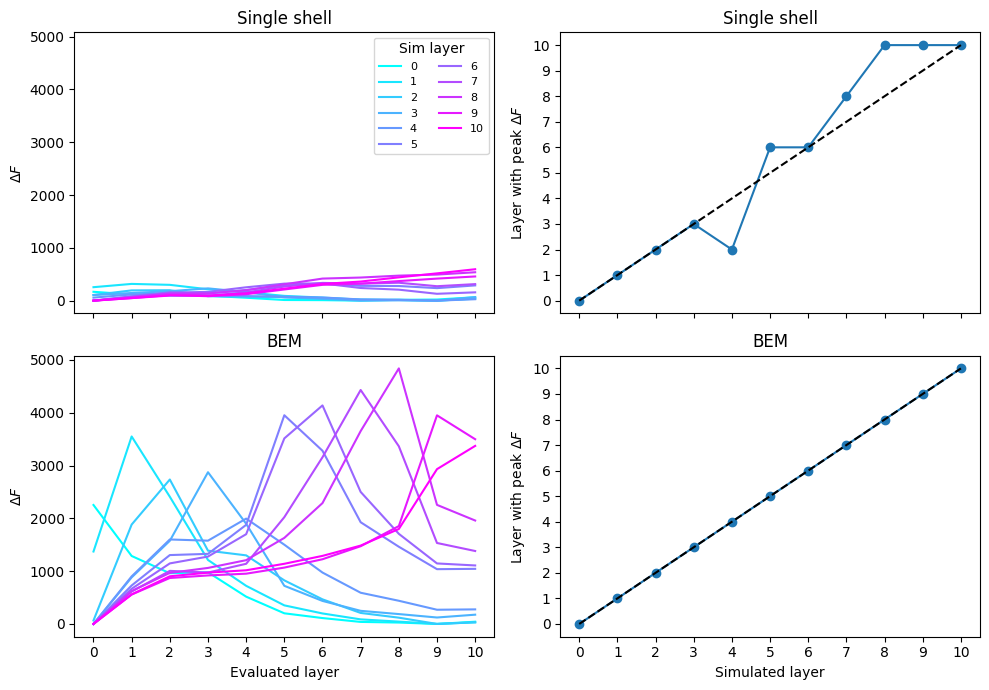

In [94]:
layers = np.arange(n_layers)
col_r = plt.cm.cool(np.linspace(0, 1, n_layers))

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex='col', sharey='col')

for row, (name, _) in enumerate(models):
    F = all_layerF[name]
    ax_curves, ax_peaks = axes[row]

    # Each colored line is one simulated depth.
    for l in layers:
        ax_curves.plot(layers, F[l] - F[l].min(), color=col_r[l], label=str(l))
    ax_curves.set_title(name)
    ax_curves.set_ylabel(r'$\Delta F$')

    # For each simulation, find the evaluated layer with the highest free energy.
    ax_peaks.plot(layers, np.argmax(F, axis=1), 'o-')
    ax_peaks.plot([0, n_layers - 1], [0, n_layers - 1], 'k--')
    ax_peaks.set_title(name)
    ax_peaks.set_ylabel(r'Layer with peak $\Delta F$')
    ax_peaks.set_yticks(layers)

axes[0, 0].legend(title='Sim layer', ncol=2, fontsize=8)
axes[1, 0].set_xlabel('Evaluated layer')
axes[1, 1].set_xlabel('Simulated layer')
for ax in axes[1]:
    ax.set_xticks(layers)

plt.tight_layout()
plt.show()

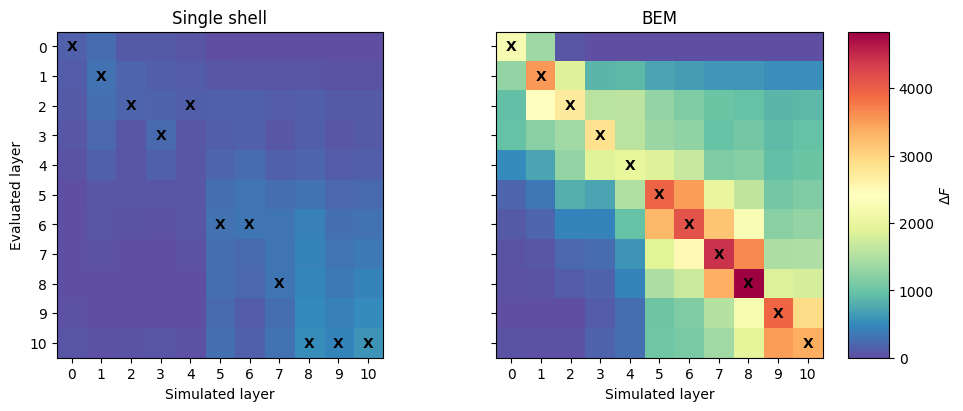

In [95]:
# Subtract the worst evaluated layer separately for each simulated recording.
relative_F = {
    name: F - F.min(axis=1, keepdims=True)
    for name, F in all_layerF.items()
}
vmax = max(F.max() for F in relative_F.values())

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True, constrained_layout=True)

for ax, (name, _) in zip(axes, models):
    F = relative_F[name]
    im = ax.imshow(F.T, cmap='Spectral_r', vmin=0, vmax=vmax, interpolation='nearest')

    for l, peak in enumerate(np.argmax(F, axis=1)):
        ax.text(l, peak, 'X', ha='center', va='center', weight='bold')

    ax.set_title(name)
    ax.set_xlabel('Simulated layer')
    ax.set_xticks(layers)
    ax.set_yticks(layers)

axes[0].set_ylabel('Evaluated layer')
fig.colorbar(im, ax=axes, label=r'$\Delta F$')
plt.show()

At this vertex, BEM reconstructs laminar activity perfectly, but single shell does not. Note that we chose the vertex to illustrate a disagreement, and the BEM also generated the data.

We'll close SPM and remove the temporary files when we're finished.

In [14]:
spm.terminate()

# Delete simulation files
shutil.rmtree(tmp_dir)